In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel
from halcyon.Trainer import Trainer
from halcyon.FittedTrainerList import FittedTrainerList
from halcyon.Losses import MSELossPlusMachineLearningL2
from copy import deepcopy
from halcyon.Simulators.GNWSimRunner import SimulationResult

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Simulating data

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [15]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [3]
sparsity_list = [0.05]
out_path = Path("../data/hybrid_model_first_tests") 

sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False
            )
            sim_outputs.append(sim_output) 
sim_outputs

2025-11-14 14:47:20,477 - INFO - Generating network
2025-11-14 14:47:21,154 - INFO - Simulating network expression over time


[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05'), network_name='my_network', nr_genes=15, nr_modules=3, sparsity=0.05, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f1d0270ba30>)]

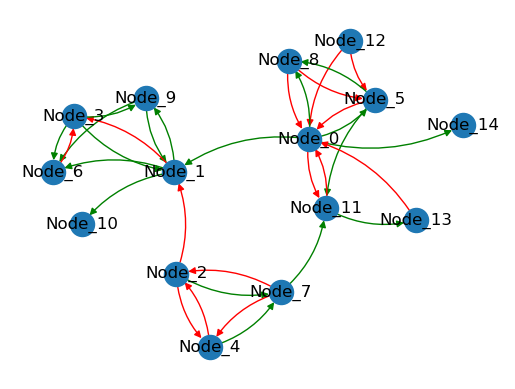

In [3]:
sim_output = sim_outputs[0]
sim_output.network.plot()
plt.show()

# Trainers (with different models) creation

In [4]:
train_jobs : list[Trainer] = []

## Mech model

In [5]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml', condition_names=(), from_gnw=True)
# Select only genes from specific module: here Nodes: 0, 11, 5, 8
mm.select_genes([f'Node_{i}' for i in [0, 11, 5, 8]])
# Fit MM on this data (skip for now?)
print(mm.modelled_gene_labels)
# Creating MM trainer even though it cannot be trained
mm_trainer = Trainer(
    mm,
    sim_output,
    batch_size=32,
    nr_training_steps=0,
    # optimizer_fn=lambda x: None
)

train_jobs.append(mm_trainer)
# mm_trainer.save(mm_trainer.save_path)

2025-11-14 14:47:31,263 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05/my_network.xml
2025-11-14 14:47:31,966 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-14 14:47:31,970 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-14 14:47:31,971 - INFO - Using CPU instead.


['Node_0', 'Node_11', 'Node_5', 'Node_8']


## ML and Hybrid model

In [6]:
expr_data = sim_output.get_no_noise_ko_timeseries_expressiondata()
# Create ML model with and without forced_positive
models_to_use = []
for force_positive, device in zip([True, False],
                                  ["cuda:0", "cuda:1"]):
    ml_model = PhoenixAddAndProdLayers(
                modelled_gene_labels=expr_data.genes,
                hidden_size=5,
                condition_names=expr_data.all_environments,
                synthesis_only_positive=force_positive,
                # device=device
        )
    
    # Create hybrid model with MM and cellbox with add and prod
    hybrid_model = HybridModel(mm, ml_model)
    
    for model in [ml_model, hybrid_model]:
        # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
        trainer = Trainer(
            model,
            sim_output,
            batch_size=32,
            nr_training_steps=500
        )
        train_jobs.append(trainer)

2025-11-14 14:47:39,581 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-14 14:47:39,582 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-14 14:47:39,583 - INFO - Using CPU instead.
2025-11-14 14:47:39,586 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-14 14:47:39,587 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-14 14:47:39,588 - INFO - Using CPU instead.
2025-11-14 14:47:39,658 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-14 14:47:39,659 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-14 14:47:39,660 - INFO - Using CPU instead.
2025-11-14 14:47:39,662 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-14 14:47:39,663 - INFO - Supported 

In [ ]:
train_jobs[-2]

In [ ]:
for job in train_jobs:
    print(job.save_path)

# Do training

In [7]:
mp.set_start_method("spawn", force=True)  
with mp.Pool(processes=8) as pool:
    pool.map(run_training_job, train_jobs)

2025-11-14 14:47:49,260 [SpawnPoolWorker-2] Epoch 0, loss 0.05152396857738495
/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))
/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))
2025-11-14 14:47:49,393 [SpawnPoolWorker-2] Epoch 1, loss 0.051286764442920685
2025-11-14 14:47:49,421 [SpawnPoolWorker-4] Epoch 0, loss 0.06069340929389
2025-11-14 14:47:4

# Plot results

In [12]:
train_jobs[0:3]

[Training PyTorchODE on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05'), network_name='my_network', nr_genes=15, nr_modules=3, sparsity=0.05, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f1d0270ba30>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05/trained_trainer_PyTorchODE.pt,
 Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05'), network_name='my_network', nr_genes=15, nr_modules=3, sparsity=0.05, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f1d0270ba30>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05/trained_trainer_PhoenixAdd

In [13]:
result_list = FittedTrainerList(train_jobs[0:3])

In [ ]:
# Currently loading hybrid / mechanistic model broken so will have to check this later. 
# The above implementation work (but doesnt load from saved files)
result_list = FittedTrainerList.from_train_jobs(train_jobs)

## Single KO

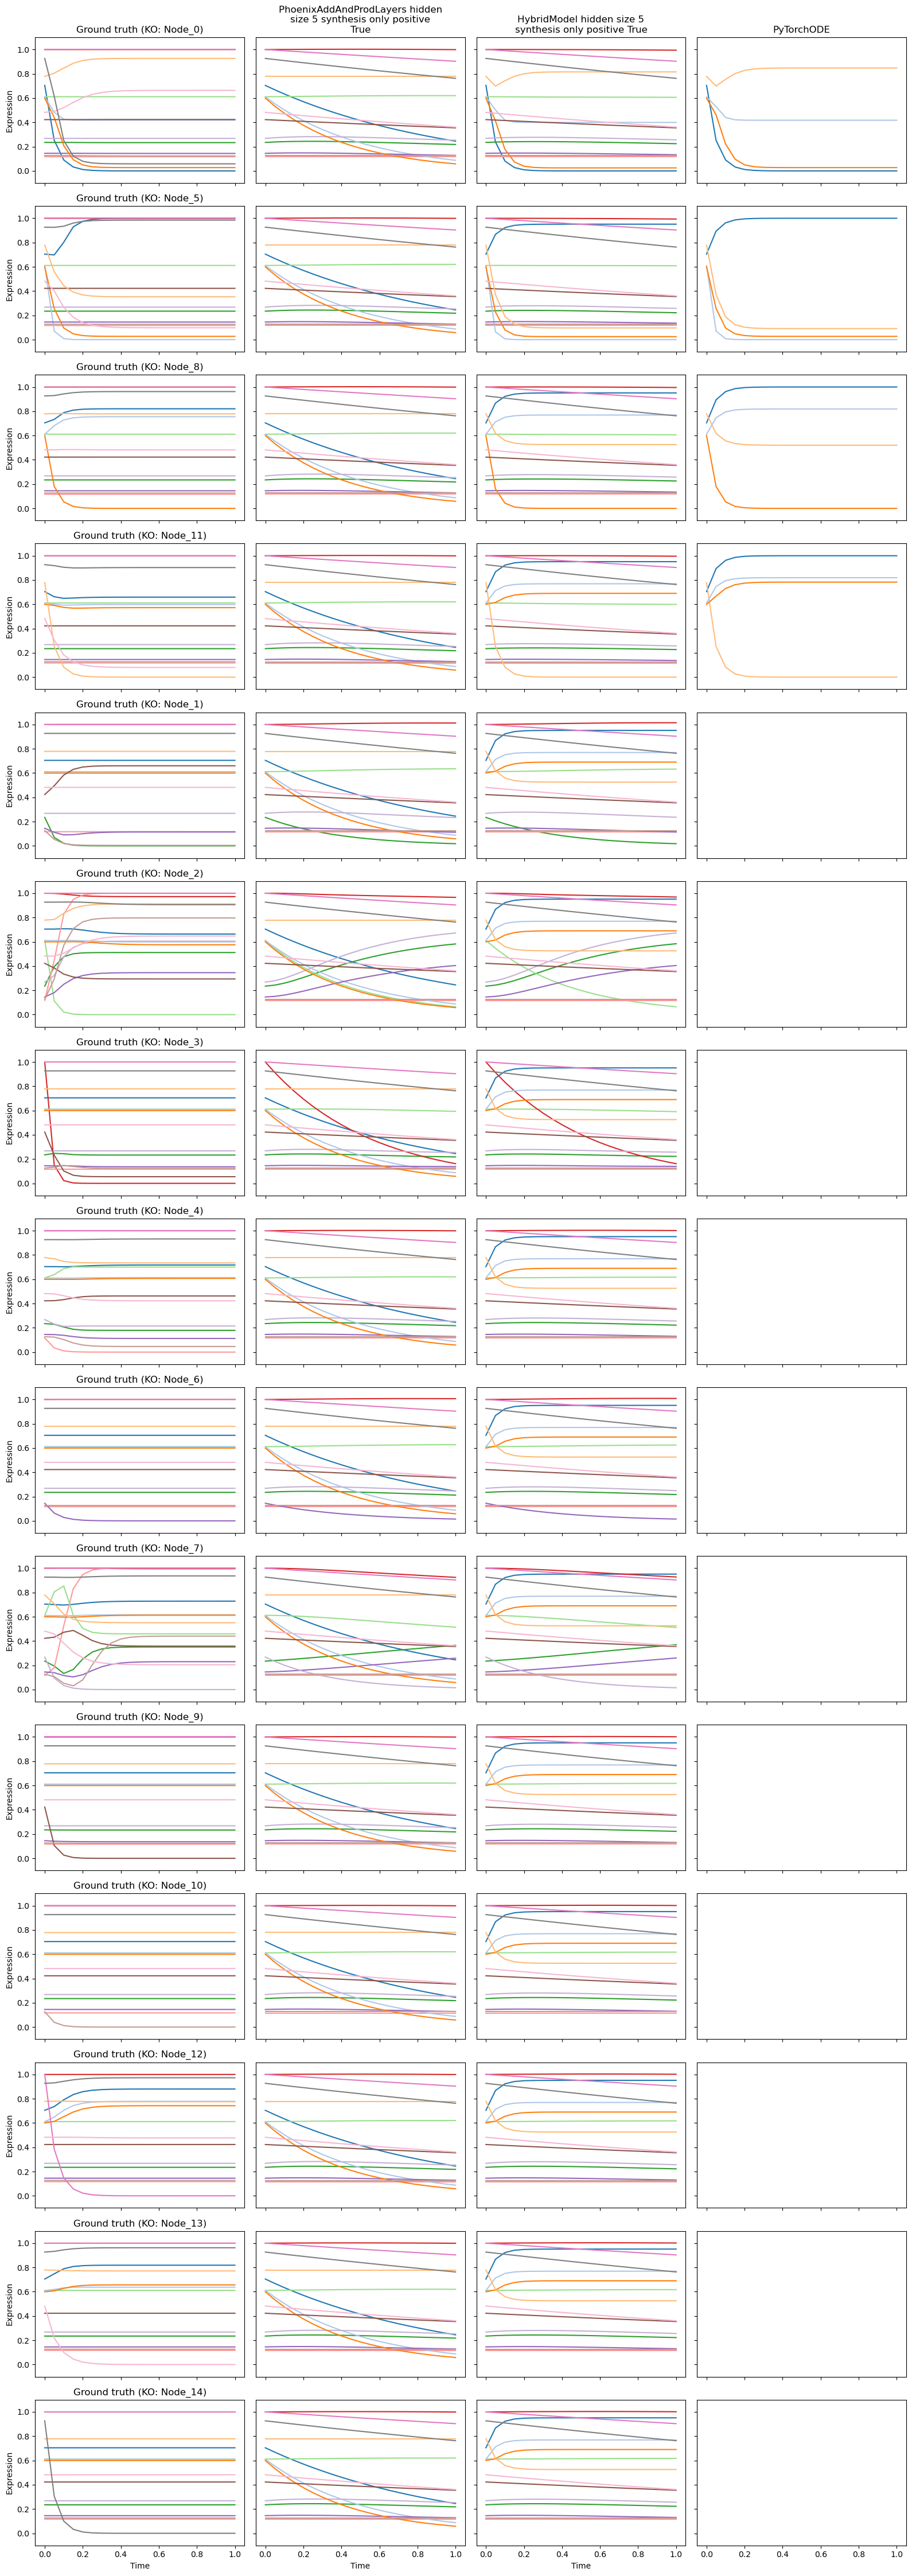

In [14]:
result_list.plot_all_model_fits_into_one_fig(ymin=-.1);plt.tight_layout();plt.show()

## Double KO (unseen)

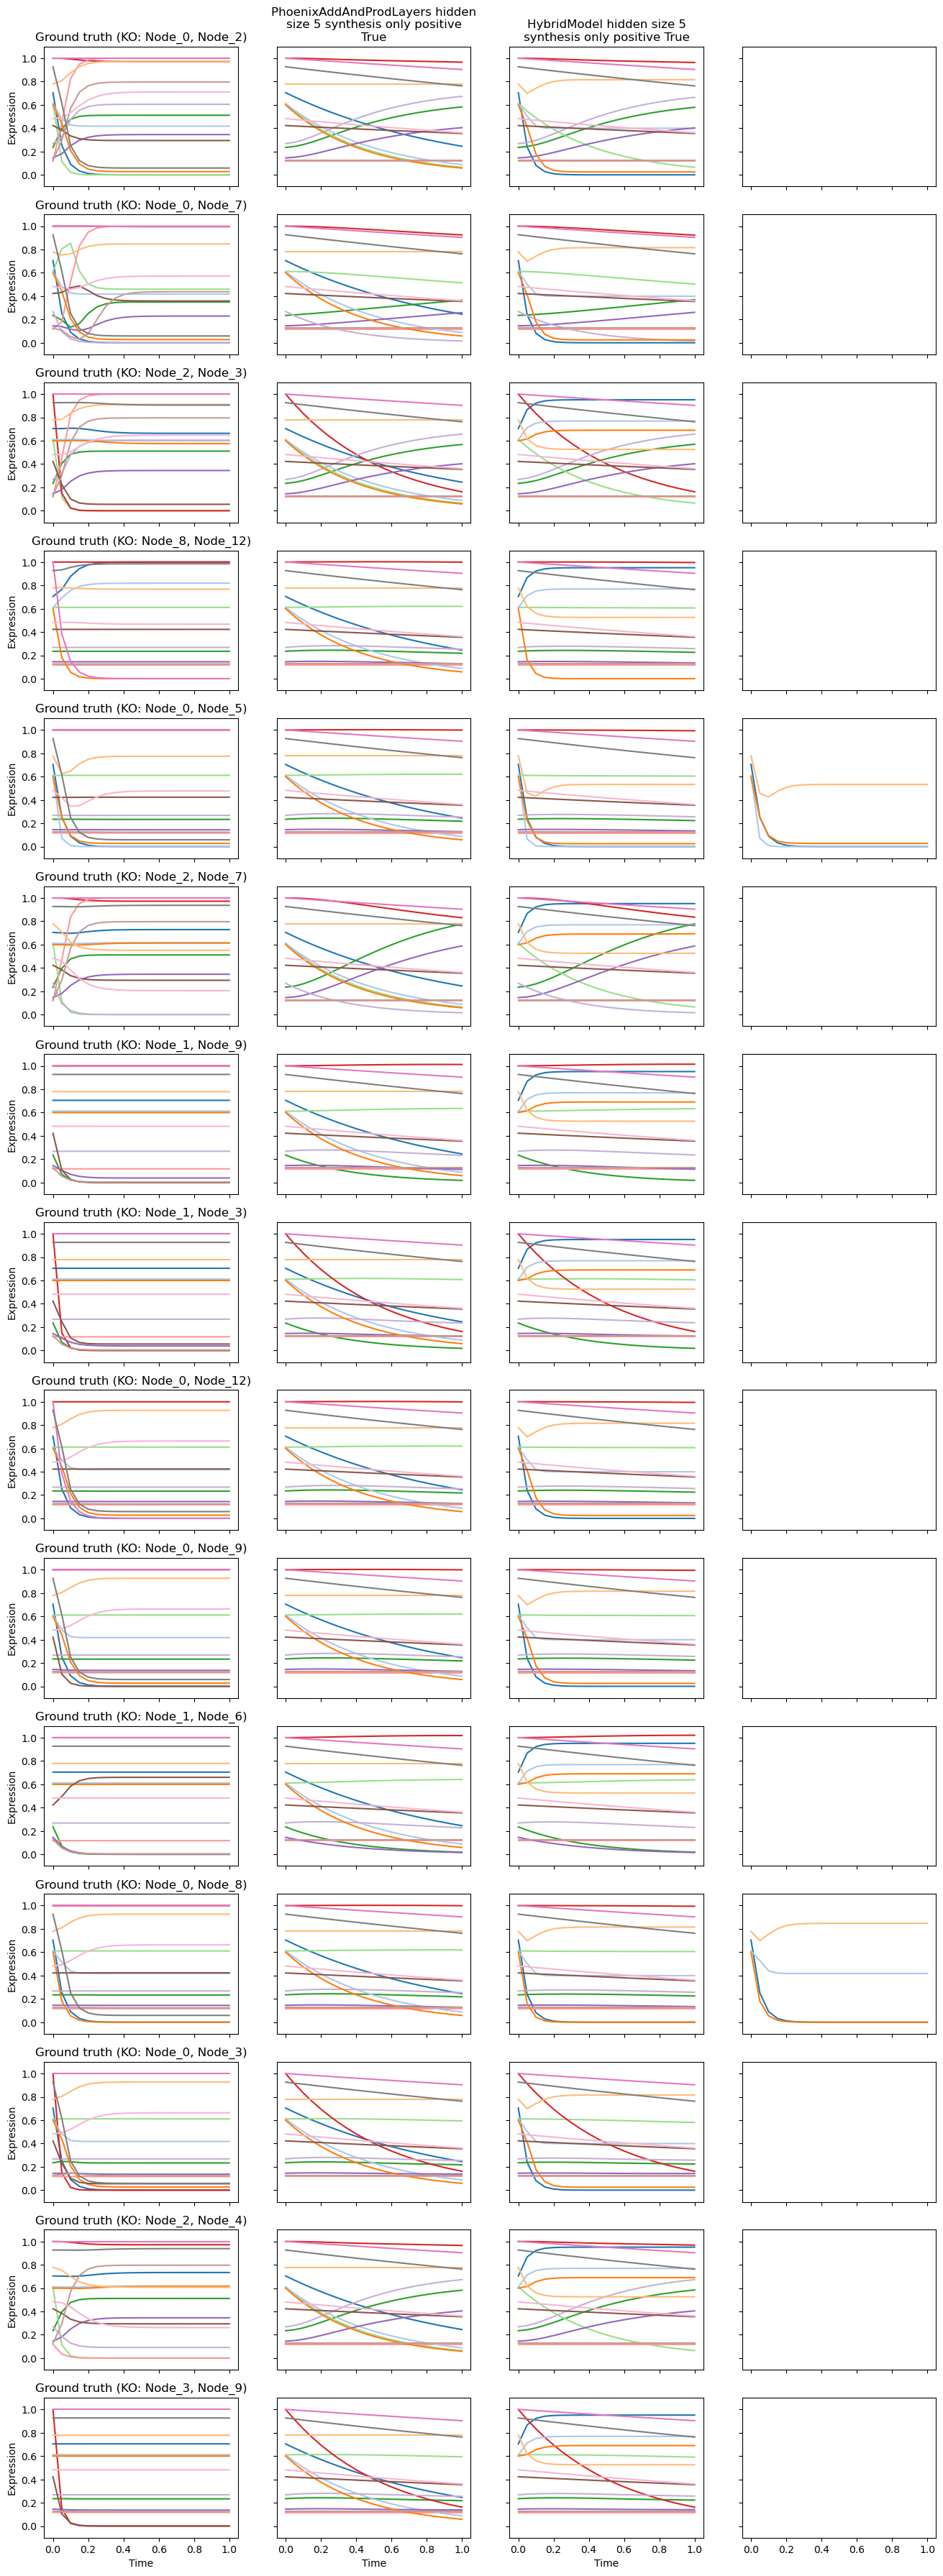

In [15]:
result_list.plot_all_model_fits_into_one_fig(only_double_ko=True, ymin=-.1);plt.show()